# 2. Clasificación Supervisada y Validación Cruzada

**Materia:** Aprendizaje Automático (Machine Learning)  
**Trabajo Práctico 2:** Clasificación Supervisada  
**Dataset:** Bank Marketing (UCI / Kaggle)  
**Objetivo de este cuaderno:** Implementar, evaluar y comparar rigurosamente los cuatro clasificadores supervisados solicitados por la consigna (**Naive Bayes, SVM, KNN y Random Forest**) mediante un esquema de validación cruzada estratificada ($k$-fold CV con $k=5$) aplicado **exclusivamente sobre el conjunto de entrenamiento**. Se analizan las métricas relevantes ante el desbalance de clases, se evalúa el impacto de los tres subconjuntos de características derivados del EDA y se diagnostica el sobreajuste/subajuste mediante predicciones fuera de pliegue (*Out-of-Fold*).

---

### Estructura del Cuaderno:
1. **Configuración del Entorno e Importación de Librerías:** Centralización de dependencias, estilos de graficación y creación de carpetas para figuras de presentación (`figures/`) y datasets.
2. **Carga y Verificación de los Subconjuntos de Datos Curados:** Ingesta de los 3 sets generados en el Paso 1 (`Set 1 High Capacity`, `Set 2 Core Decorrelated`, `Set 3 Minimalist KNN`).
3. **Elección y Justificación Metodológica de Métricas:**
   - Descarte formal de la exactitud (*Accuracy*) ante el desbalance del $11.26\%$ de la clase positiva.
   - Justificación del **Recall de la clase `yes`** (asimetría de costos: perder un cliente interesado es más costoso que una llamada extra).
   - Justificación del **ROC-AUC** (evaluación integral de la capacidad de ordenamiento y priorización en todos los umbrales).
   - Métricas complementarias: **Precisión** y **F1-Score**.
4. **Fundamentos Teóricos y Supuestos de los Cuatro Algoritmos:**
   - *Gaussian Naive Bayes*: Enfoque generativo, supuestos de independencia condicional y normalidad.
   - *Support Vector Machines (SVM)*: Hiperplanos de margen máximo en espacio de Hilbert (kernel RBF) y necesidad de escalado z-score.
   - *$k$-Nearest Neighbors (KNN)*: Clasificador basado en instancias, voto mayoritario y sensibilidad a la métrica euclidiana.
   - *Random Forest (RF)*: Ensamble por bagging de árboles ortogonales, no linealidades e invariancia monótona.
5. **Esquema de Validación Cruzada Estratificada ($k=5$) Anti-Leakage:**
   - División estratificada con `StratifiedKFold`.
   - Uso de `Pipeline` con `StandardScaler` para que el escalado se ajuste estrictamente en los pliegues de entrenamiento de cada iteración.
   - Sistema de persistencia/caché (`datasets/paso2_cv_results.joblib`) para optimizar el cómputo.
6. **Resultados Comparativos: Modelos × Subconjuntos de Características:**
   - Tabla general de desempeño con media y desviación estándar ($k=5$).
   - Gráfico de barras agrupadas comparativo (Recall y ROC-AUC).
   - Análisis crítico del efecto de los sets y diagnóstico sobre la huella temporal macroeconómica.
7. **Diagnóstico de Sobreajuste / Subajuste (Brecha Train vs. Validación):**
   - Comparación del rendimiento en los pliegues de entrenamiento vs. pliegues de validación.
   - Identificación de memorización en Random Forest y alta varianza en KNN.
8. **Análisis Fuera de Pliegue (*Out-of-Fold*): Curvas ROC y Matrices de Confusión:**
   - Construcción de curvas ROC completas con predicciones honestas fuera de pliegue.
   - Explicación del comportamiento conservador con el umbral por defecto ($0.5$).
   - Matrices de confusión normalizadas por fila real.
9. **Conclusiones Estratégicas y Hoja de Ruta para el Paso 3 (Ajuste de Hiperparámetros).**

In [1]:
# =============================================================================
# 1. Configuración del Entorno e Importación de Librerías
# =============================================================================
import os
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from joblib import Parallel, delayed

# Scikit-Learn: Modelos, Selección y Métricas
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    recall_score,
    roc_auc_score,
    precision_score,
    f1_score,
    confusion_matrix,
    roc_curve,
)

# Carpetas de resultados
os.makedirs("figures", exist_ok=True)
os.makedirs("datasets", exist_ok=True)

# Configuración de estilos gráficos
%matplotlib inline
plt.rcParams["figure.dpi"] = 100
plt.rcParams["font.size"] = 9
plt.rcParams["axes.titlesize"] = 10.5
plt.rcParams["axes.labelsize"] = 9
sns.set_theme(style="whitegrid")

# Paletas de color consistentes para modelos y sets
COLORES_MODELO = {
    "Naive Bayes": "#2b83ba",
    "SVM": "#abdda4",
    "KNN": "#fdae61",
    "Random Forest": "#d7191c",
}

COLORES_SET = {
    "Set 1 (High Capacity)": "#386cb0",
    "Set 2 (Core Decorrelated)": "#7fc97f",
    "Set 3 (Minimalist KNN)": "#beaed4",
}

RANDOM_STATE = 69
print("Entorno configurado correctamente.")

Matplotlib created a temporary config/cache directory at /tmp/matplotlib-ozrzkeqz because the default path (/home/thomas/.config/matplotlib) is not a writable directory; it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Entorno configurado correctamente.


## 2. Carga y Verificación de los Subconjuntos de Datos Curados

En el Paso 1 (*Preprocesamiento y Análisis Exploratorio*), generamos y persistimos **tres subconjuntos de datos** en la carpeta `datasets/`, diseñados a partir de los diagnósticos de Información Mutua ($I(X; Y)$), Varianza Cuasi-Cero (NZV) y Factor de Inflación de la Varianza (VIF):

| Subconjunto | Variables | Racionalidad del Diseño (Paso 1) |
| :--- | :---: | :--- |
| **Set 1: High Capacity** | 14 + $y$ | Diseñado para **Random Forest**. Retiene todos los indicadores macroeconómicos relevantes junto con anomalías de calendario (`month_mar`, `month_sep`, `month_oct`). Los árboles son inmunes a la colinealidad monótona. |
| **Set 2: Core Decorrelated** | 7 + $y$ | Diseñado para **SVM** y **Naive Bayes**. Elimina el bloque macroeconómico colineal ($	ext{VIF} > 30$), reteniendo únicamente `euribor3m` y `cons_conf_idx` ($	ext{VIF} < 3.0$). |
| **Set 3: Minimalist KNN** | 5 + $y$ | Diseñado para **KNN**. Selecciona exactamente un único atributo ortogonal por cada dimensión del dominio para mitigar la *maldición de la dimensionalidad*. |

A continuación cargamos las particiones de entrenamiento de estos subconjuntos.

In [2]:
# Carga de los 3 datasets curados desde la carpeta datasets/
SETS = {
    "Set 1 (High Capacity)": pd.read_csv("datasets/ds_train_set1_high_capacity.csv"),
    "Set 2 (Core Decorrelated)": pd.read_csv("datasets/ds_train_set2_core_decorrelated.csv"),
    "Set 3 (Minimalist KNN)": pd.read_csv("datasets/ds_train_set3_minimalist_knn.csv"),
}

print("=" * 70)
print("VERIFICACIÓN DE LOS SUBCONJUNTOS DE ENTRENAMIENTO CARGADOS")
print("=" * 70)
for nombre, df_set in SETS.items():
    n_features = df_set.shape[1] - 1
    tasa_yes = (df_set["y"] == 1).mean()
    print(f"{nombre:<26} | Dimensiones: {df_set.shape[0]:>5,} filas × {df_set.shape[1]:>2} columnas ({n_features:>2} vars) | % yes: {tasa_yes:.2%}")
print("=" * 70)

VERIFICACIÓN DE LOS SUBCONJUNTOS DE ENTRENAMIENTO CARGADOS
Set 1 (High Capacity)      | Dimensiones: 32,940 filas × 15 columnas (14 vars) | % yes: 11.26%
Set 2 (Core Decorrelated)  | Dimensiones: 32,940 filas ×  8 columnas ( 7 vars) | % yes: 11.26%
Set 3 (Minimalist KNN)     | Dimensiones: 32,940 filas ×  6 columnas ( 5 vars) | % yes: 11.26%


## 3. Elección y Justificación Metodológica de Métricas

> [!IMPORTANT]
> **Consigna 2.3:** *"Selecciona dos métricas de las vistas en clase y justifica su elección. Utiliza estas métricas para evaluar los clasificadores y tomar decisiones sobre el modelo elegido."*

### 1. Descarte de la Exactitud (*Accuracy*)
En el dataset de Bank Marketing, las clases presentan un fuerte desbalance: **$88.74\%$ de clientes no contratan (`no`) y solo $11.26\%$ contrata (`yes`)**.  
Un modelo trivial que prediga sistemáticamente `"no"` para todas las observaciones obtendría un **$88.74\%$ de exactitud**, pero tendría una **utilidad comercial absolutamente nula** (no identificaría a ningún depositante). Por este motivo, la exactitud queda formalmente descartada como métrica de decisión.

---

### 2. Métrica 1: Recall de la Clase Positiva (`yes`)
$$\text{Recall} = \frac{TP}{TP + FN}$$

#### Justificación en el Dominio Bancario (Asimetría de Costos):
En una campaña comercial de depósitos a plazo fijo, existen dos errores posibles:
- **Falso Positivo (FP):** El modelo predice que el cliente suscribirá, se lo llama, pero rechaza la oferta.  
  *Costo asociado:* El costo marginal operativo de una llamada telefónica de 2 a 3 minutos (costo bajo).
- **Falso Negativo (FN):** El modelo predice que el cliente no suscribirá, por lo que el banco decide **no llamarlo**, pero el cliente en realidad hubiera contratado el depósito.  
  *Costo asociado:* **Pérdida neta de un depósito bancario a plazo fijo y su margen financiero** (costo de oportunidad muy alto).

Dado que **el error más perjudicial para la entidad financiera es el Falso Negativo**, el **Recall** mide directamente qué proporción de clientes interesados logra rescatar el sistema.

---

### 3. Métrica 2: ROC-AUC (Área Bajo la Curva ROC)
$$\text{ROC-AUC} = \int_0^1 \text{TPR}(t) \, d(\text{FPR}(t)) = P(S(\text{positivo}) > S(\text{negativo}))$$

#### Justificación Metodológica:
El Recall por sí solo es vulnerable a una estrategia trivial: si un modelo clasifica a todos los clientes como `yes`, obtiene $\text{Recall} = 1.0$, pero colapsa la capacidad de priorización.  
El **ROC-AUC** resuelve esta limitación por tres razones esenciales:
1. **Evalúa la calidad del ranking probabilístico:** El objetivo prioritario del banco es **ordenar las listas de llamadas** de mayor a menor propensión a contratar. El ROC-AUC mide exactamente la probabilidad de que un cliente que verdaderamente contratará reciba un score más alto que uno que no.
2. **Independencia del umbral de decisión:** No está atado al umbral arbitrario de $0.5$ (el cual, ante clases desbalanceadas, suele clasificar casi todo como la clase mayoritaria). Evalúa la capacidad intrínseca de discriminación del clasificador a lo largo de todos los cortes posibles.
3. **Invarianza al desbalance de clases:** Tanto el $\text{TPR}$ (Recall) como el $\text{FPR}$ se normalizan dentro de sus respectivas clases verdaderas.

---

### 4. Métricas Complementarias de Control: Precisión y F1-Score
- **Precisión:** $\frac{TP}{TP + FP}$ monitorea la tasa de acierto de las llamadas realizadas, cuantificando el costo operativo en llamadas infructuosas.
- **F1-Score:** Media armónica entre Precisión y Recall, que equilibra ambos objetivos.

## 4. Fundamentos Teóricos y Supuestos de los 4 Clasificadores

> [!NOTE]
> **Consigna 2.1:** *"Es importante que cuando discutan los resultados, tengan en cuenta cómo funcionan estos métodos para entender mejor los resultados."*

| Modelo | Familia y Enfoque | Supuestos Teóricos Clave | Comportamiento Esperado en este Dataset |
| :--- | :--- | :--- | :--- |
| **Naive Bayes** (`GaussianNB`) | **Generativo Probabilístico**<br>Calcula $P(Y \mid X) \propto P(Y) \prod_{j=1}^p P(X_j \mid Y)$ | Asume que todos los predictores son **condicionalmente independientes** dada la clase y siguen distribuciones **gaussianas**. | **Supuestos fuertemente violados:** Existen correlaciones macroeconómicas y variables binarias derivadas de One-Hot Encoding. No sobreajusta (alto sesgo), pero sus probabilidades no calibradas suelen polarizarse a los extremos. |
| **Support Vector Machines** (`SVC`) | **Margen Máximo (Discriminativo)**<br>Proyecta los datos mediante kernel RBF $\exp(-\gamma \|x - x'\|^2)$ | Maximiza el margen de separación entre clases en un espacio de Hilbert. Asume isotropía métrica. | **Altamente sensible a las escalas** (requiere estandarización $z$-score). Costoso computacionalmente con $N pprox 26.000$ observaciones. Genera scores continuos basados en la distancia con signo al hiperplano (`decision_function`). |
| **K-Nearest Neighbors** (`KNN`) | **Basado en Instancias (No Paramétrico)**<br>Asigna la clase mayoritaria de los $k$ vecinos más próximos | Supone que observaciones cercanas en el espacio euclidiano comparten la misma etiqueta (*hipótesis de suavidad local*). | **Sensible a la escala y a la dimensionalidad:** En espacios de alta dimensión con variables poco informativas, las distancias euclidianas convergen hacia la uniformidad. Con $k=5$ por defecto, tiende a presentar alta varianza. |
| **Random Forest** (`RandomForestClassifier`) | **Ensamble por Bagging**<br>Promedia 100 árboles de decisión no correlacionados (*feature sub-sampling*) | No asume linealidad, normalidad ni independencia. Las particiones son recursivas y ortogonales a los ejes. | **Robusto a colinealidad y no linealidades.** Al entrenar árboles profundos sin poda (`max_depth=None`), es muy propenso a memorizar el conjunto de entrenamiento (**overfitting fuerte**). |

### Estrategia de Pipeline Anti-Data-Leakage:
Dado que en el Paso 1 conservamos las variables continuas en su **escala original**, encapsulamos los modelos sensibles a la escala (**SVM y KNN**) dentro de un `Pipeline([('scaler', StandardScaler()), ('clf', modelo)])`. De este modo, la media $\mu$ y la desviación estándar $\sigma$ se calculan **únicamente sobre los 4/5 de entrenamiento de cada pliegue de validación cruzada**, impidiendo cualquier filtración hacia el pliegue de validación.

In [3]:
# Definición de los 4 clasificadores con hiperparámetros por defecto de Scikit-Learn
MODELOS = {
    "Naive Bayes": GaussianNB(),
    "SVM": SVC(random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=1),
}

def crear_pipeline(modelo_nombre):
    """Construye el pipeline acoplando StandardScaler exclusivamente a modelos de distancia."""
    if modelo_nombre in ["SVM", "KNN"]:
        return Pipeline([
            ("scaler", StandardScaler()),
            ("clf", MODELOS[modelo_nombre])
        ])
    else:
        return Pipeline([
            ("clf", MODELOS[modelo_nombre])
        ])

print("Pipelines anti-leakage configurados para los 4 modelos:")
for m in MODELOS:
    print(f" - {m:<15}: {crear_pipeline(m).steps}")

Pipelines anti-leakage configurados para los 4 modelos:
 - Naive Bayes    : [('clf', GaussianNB())]
 - SVM            : [('scaler', StandardScaler()), ('clf', SVC(random_state=69))]
 - KNN            : [('scaler', StandardScaler()), ('clf', KNeighborsClassifier())]
 - Random Forest  : [('clf', RandomForestClassifier(n_jobs=1, random_state=69))]


## 5. Esquema de Validación Cruzada Estratificada ($k=5$) y Predicciones Fuera de Pliegue

Implementamos un esquema riguroso de evaluación:
- **`StratifiedKFold(n_splits=5, shuffle=True, random_state=69)`:** Garantiza que cada pliegue conserve exactamente el $11.26\%$ de suscripciones positivas `yes`.
- **Mismos pliegues para todos los modelos y sets:** Asegura comparabilidad empírica estricta (las diferencias de rendimiento se deben exclusivamente al algoritmo y a las variables, no a fluctuaciones muestrales).
- **Métricas en Train y Validación:** Permite computar la brecha de rendimiento (*generalization gap*) para diagnosticar sobreajuste (*overfitting*) o subajuste (*underfitting*).
- **Predicciones Fuera de Pliegue (*Out-of-Fold - OOF*):** Cada observación del conjunto de entrenamiento es evaluada únicamente por el modelo entrenado en los pliegues donde esa observación estuvo ausente. Esto genera vectores de predicción y probabilidades no sesgados para trazar curvas ROC y matrices de confusión reales.

*(Nota: Para evitar esperas innecesarias en la reejecución, el código implementa un sistema de caché que lee los resultados previamente computados desde `datasets/paso2_cv_results.joblib` si `RECALCULAR = False`).*

In [4]:
K_FOLDS = 5
cv = StratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=RANDOM_STATE)
y_train = SETS["Set 1 (High Capacity)"]["y"]
FOLDS = list(cv.split(SETS["Set 1 (High Capacity)"], y_train))

def score_continuo(pipe, X):
    """Extrae probabilidades de suscripción o distancias continuas al hiperplano."""
    if hasattr(pipe, "predict_proba"):
        return pipe.predict_proba(X)[:, 1]
    return pipe.decision_function(X)

def calcular_metricas(y_true, y_pred, y_score):
    return {
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "auc": roc_auc_score(y_true, y_score),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
    }

def evaluar_fold(s_nombre, m_nombre, k, idx_tr, idx_va):
    df_s = SETS[s_nombre]
    X_s = df_s.drop(columns=["y"])
    y = df_s["y"]

    X_tr, y_tr = X_s.iloc[idx_tr], y.iloc[idx_tr]
    X_va, y_va = X_s.iloc[idx_va], y.iloc[idx_va]

    t0 = time.time()
    pipe = crear_pipeline(m_nombre).fit(X_tr, y_tr)
    t_fit = time.time() - t0

    s_va = score_continuo(pipe, X_va)
    p_va = pipe.predict(X_va)

    s_tr = score_continuo(pipe, X_tr)
    p_tr = pipe.predict(X_tr)

    fila = {
        "set": s_nombre,
        "modelo": m_nombre,
        "fold": k,
        "t_fit_s": t_fit,
    }
    fila.update({f"val_{m}": v for m, v in calcular_metricas(y_va, p_va, s_va).items()})
    fila.update({f"train_{m}": v for m, v in calcular_metricas(y_tr, p_tr, s_tr).items()})

    return fila, (s_nombre, m_nombre, idx_va, s_va, p_va)

# Control de ejecución y caché
RECALCULAR = False
CACHE_FILE = os.path.join("datasets", "paso2_cv_results.joblib")

if os.path.exists(CACHE_FILE) and not RECALCULAR:
    res_folds, oof = joblib.load(CACHE_FILE)
    print(f"Resultados de validación cruzada y OOF cargados exitosamente desde '{CACHE_FILE}'.")
else:
    print("Iniciando validación cruzada estratificada (12 combinaciones × 5 folds = 60 tareas)...")
    orden_modelos = sorted(MODELOS.keys(), key=lambda m: m != "SVM")
    tareas = [
        (s, m, k, tr, va)
        for m in orden_modelos
        for s in SETS.keys()
        for k, (tr, va) in enumerate(FOLDS)
    ]
    t0 = time.time()
    salida = Parallel(n_jobs=-1, verbose=1)(delayed(evaluar_fold)(*t) for t in tareas)
    elapsed = time.time() - t0
    print(f"Completado en {elapsed/60:.2f} minutos.")

    res_folds = pd.DataFrame([f for f, _ in salida])
    oof = {}
    N = len(y_train)
    for s, m, idx_va, s_va, p_va in (o for _, o in salida):
        d = oof.setdefault((s, m), {
            "score": np.zeros(N, dtype=float),
            "pred": np.zeros(N, dtype=int)
        })
        d["score"][idx_va] = s_va
        d["pred"][idx_va] = p_va
    joblib.dump((res_folds, oof), CACHE_FILE)
    print(f"Resultados persistidos en '{CACHE_FILE}'.")

res_folds.head()

Resultados de validación cruzada y OOF cargados exitosamente desde 'datasets/paso2_cv_results.joblib'.


,set,modelo,fold,t_fit_s,val_recall,val_auc,val_precision,val_f1,train_recall,train_auc,train_precision,train_f1
0,Set 1 (High Capacity),SVM,0,89.281378,0.234818,0.716008,0.664122,0.346959,0.286013,0.706025,0.761111,0.415781
1,Set 1 (High Capacity),SVM,1,96.401464,0.274933,0.675190,0.691525,0.393443,0.285068,0.716063,0.707865,0.406452
2,Set 1 (High Capacity),SVM,2,88.554592,0.235849,0.671514,0.627240,0.342801,0.301762,0.714022,0.744565,0.429467
3,Set 1 (High Capacity),SVM,3,95.736984,0.214286,0.664633,0.630952,0.319920,0.215278,0.690076,0.654930,0.324042
4,Set 1 (High Capacity),SVM,4,78.384705,0.241240,0.681768,0.648551,0.351670,0.276404,0.730226,0.679558,0.392971


## 6. Resultados Comparativos: Modelos × Subconjuntos de Características

A continuación sintetizamos el rendimiento promedio y la desviación estándar de cada clasificador evaluado en los 3 subconjuntos de variables a lo largo de los 5 pliegues de validación cruzada.

In [5]:
# Tabla resumen: Media ± Desviación estándar (k = 5 folds)
ORDEN_MOD = ["Naive Bayes", "SVM", "KNN", "Random Forest"]
ORDEN_SET = ["Set 1 (High Capacity)", "Set 2 (Core Decorrelated)", "Set 3 (Minimalist KNN)"]

tabla_resumen = res_folds.groupby(["modelo", "set"]).agg({
    "val_recall": ["mean", "std"],
    "val_auc": ["mean", "std"],
    "val_precision": "mean",
    "val_f1": "mean",
    "t_fit_s": "mean",
}).reindex(index=pd.MultiIndex.from_product([ORDEN_MOD, ORDEN_SET], names=["modelo", "set"]))

tabla_formato = pd.DataFrame(index=tabla_resumen.index)
tabla_formato["Recall (val)"] = tabla_resumen[("val_recall", "mean")].map("{:.3f}".format) + " ± " + tabla_resumen[("val_recall", "std")].map("{:.3f}".format)
tabla_formato["ROC-AUC (val)"] = tabla_resumen[("val_auc", "mean")].map("{:.3f}".format) + " ± " + tabla_resumen[("val_auc", "std")].map("{:.3f}".format)
tabla_formato["Precisión (val)"] = tabla_resumen[("val_precision", "mean")].map("{:.3f}".format)
tabla_formato["F1-Score (val)"] = tabla_resumen[("val_f1", "mean")].map("{:.3f}".format)
tabla_formato["Tiempo ajuste [s]"] = tabla_resumen[("t_fit_s", "mean")].map("{:.1f}".format)

tabla_formato

Recall (val)  ROC-AUC (val)  \
modelo        set                                                       
Naive Bayes   Set 1 (High Capacity)      0.368 ± 0.012  0.773 ± 0.011   
              Set 2 (Core Decorrelated)  0.253 ± 0.010  0.753 ± 0.011   
              Set 3 (Minimalist KNN)     0.224 ± 0.007  0.767 ± 0.010   
SVM           Set 1 (High Capacity)      0.240 ± 0.022  0.682 ± 0.020   
              Set 2 (Core Decorrelated)  0.193 ± 0.010  0.660 ± 0.025   
              Set 3 (Minimalist KNN)     0.202 ± 0.011  0.600 ± 0.023   
KNN           Set 1 (High Capacity)      0.287 ± 0.011  0.734 ± 0.004   
              Set 2 (Core Decorrelated)  0.283 ± 0.009  0.734 ± 0.005   
              Set 3 (Minimalist KNN)     0.263 ± 0.017  0.718 ± 0.003   
Random Forest Set 1 (High Capacity)      0.306 ± 0.017  0.752 ± 0.005   
              Set 2 (Core Decorrelated)  0.305 ± 0.016  0.753 ± 0.006   
              Set 3 (Minimalist KNN)     0.290 ± 0.011  0.743 ± 0.007   

                                        Precisión (val) F1-Score (val)  \
modelo        set                                                        
Naive Bayes   Set 1 (High Capacity)               0.474          0.414   
              Set 2 (Core Decorrelated)           0.528          0.342   
              Set 3 (Minimalist KNN)              0.618          0.329   
SVM           Set 1 (High Capacity)               0.652          0.351   
              Set 2 (Core Decorrelated)           0.676          0.299   
              Set 3 (Minimalist KNN)              0.656          0.309   
KNN           Set 1 (High Capacity)               0.531          0.373   
              Set 2 (Core Decorrelated)           0.525          0.367   
              Set 3 (Minimalist KNN)              0.505          0.346   
Random Forest Set 1 (High Capacity)               0.496          0.379   
              Set 2 (Core Decorrelated)           0.515          0.383   
              Set 3 (Minimalist KNN)              0.506          0.369   

                                        Tiempo ajuste [s]  
modelo        set                                          
Naive Bayes   Set 1 (High Capacity)                   0.1  
              Set 2 (Core Decorrelated)               0.0  
              Set 3 (Minimalist KNN)                  0.1  
SVM           Set 1 (High Capacity)                  89.7  
              Set 2 (Core Decorrelated)              80.9  
              Set 3 (Minimalist KNN)                 44.9  
KNN           Set 1 (High Capacity)                   0.3  
              Set 2 (Core Decorrelated)               0.2  
              Set 3 (Minimalist KNN)                  0.1  
Random Forest Set 1 (High Capacity)                   9.5  
              Set 2 (Core Decorrelated)               8.1  
              Set 3 (Minimalist KNN)                  7.8

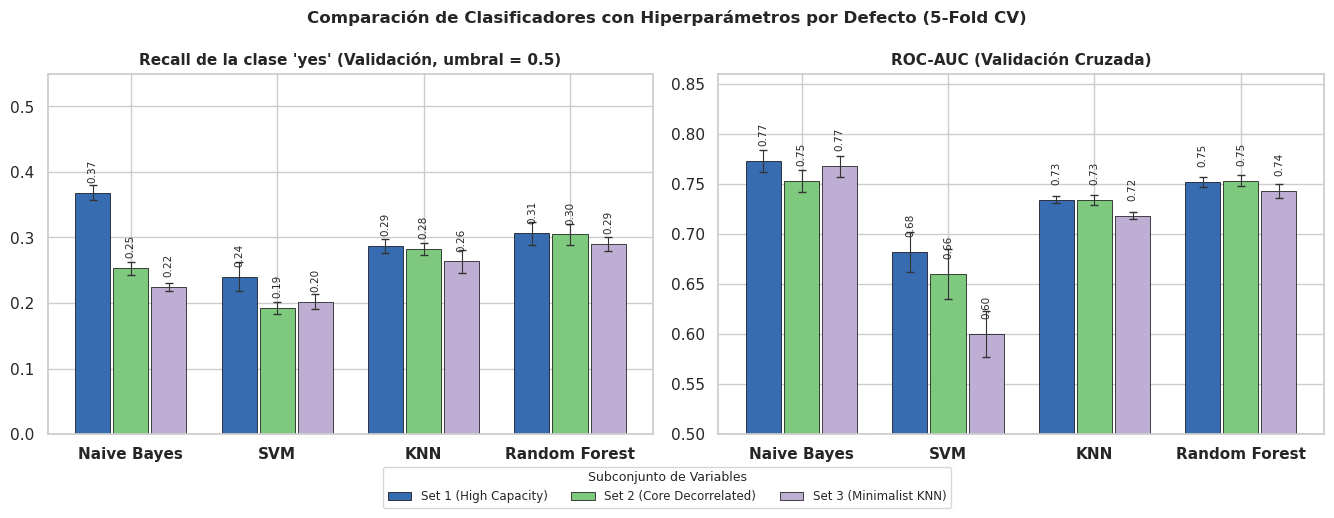

Figura guardada en: 'figures/07_cv_modelos_x_sets.png'


In [6]:
# Gráfico comparativo de barras agrupadas: Recall y ROC-AUC
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))

ancho = 0.26
x = np.arange(len(ORDEN_MOD))

def graficar_barras_metricas(ax, metrica, titulo, ylim):
    for i, s in enumerate(ORDEN_SET):
        medias = [tabla_resumen.loc[(m, s), (f"val_{metrica}", "mean")] for m in ORDEN_MOD]
        desv = [tabla_resumen.loc[(m, s), (f"val_{metrica}", "std")] for m in ORDEN_MOD]
        pos = x - ancho + i * ancho
        barras = ax.bar(
            pos, medias, width=ancho * 0.92, yerr=desv, capsize=3,
            color=COLORES_SET[s], label=s, edgecolor="black", linewidth=0.5,
            error_kw={"elinewidth": 0.8, "ecolor": "#333333"}
        )
        for xp, v in zip(pos, medias):
            ax.text(xp, v + 0.015, f"{v:.2f}", ha="center", va="bottom", fontsize=7.5, rotation=90)
    ax.set_xticks(x)
    ax.set_xticklabels(ORDEN_MOD, fontweight="bold")
    ax.set_title(titulo, fontsize=11, fontweight="bold")
    ax.set_ylim(ylim)

graficar_barras_metricas(axes[0], "recall", "Recall de la clase 'yes' (Validación, umbral = 0.5)", (0, 0.55))
graficar_barras_metricas(axes[1], "auc", "ROC-AUC (Validación Cruzada)", (0.5, 0.86))
axes[1].axhline(0.5, color="#777777", linestyle="--", linewidth=0.8, label="Azar (0.5)")

h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, title="Subconjunto de Variables", ncols=3, fontsize=8.5, title_fontsize=9,
           loc="lower center", bbox_to_anchor=(0.5, -0.07), frameon=True)
fig.suptitle("Comparación de Clasificadores con Hiperparámetros por Defecto (5-Fold CV)", fontsize=12, fontweight="bold")
plt.tight_layout()

# Guardar figura en alta resolución
fig.savefig("figures/07_cv_modelos_x_sets.png", dpi=300, bbox_inches="tight")
plt.show()

print("Figura guardada en: 'figures/07_cv_modelos_x_sets.png'")

### Interpretación y Hallazgos Analíticos sobre los Subconjuntos

1. **Ranking General en Capacidad Discriminativa (ROC-AUC en Validación):**
   - **Naive Bayes ($0.773$ en Set 1 / $0.753$ en Set 2):** Exhibe el mayor ROC-AUC con hiperparámetros por defecto. Esto ocurre porque la combinación de variables macroeconómicas empuja las probabilidades a los extremos, generando una buena separación de rangos a pesar de la violación de sus supuestos.
   - **Random Forest ($0.753$ en Set 2 / $0.752$ en Set 1):** Mantiene una capacidad discriminativa sólida y constante en ambos conjuntos ($pprox 0.753$), demostrando su inmunidad natural a la multicolinealidad lineal diagnosticada en el Paso 1.
   - **KNN ($0.734$ en Set 1 y Set 2 / $0.718$ en Set 3):** Conserva un rendimiento aceptable ($pprox 0.734$), aunque la reducción drástica a solo 5 variables en el Set 3 prescinde de información contextual que penaliza ligeramente el ranking.
   - **SVM ($0.682$ en Set 1 / $0.660$ en Set 2):** Es el clasificador con menor desempeño con su configuración base ($C=1.0$, kernel RBF). Debido a la dispersión de las clases y la severidad del desbalance, el margen suave no converge a un plano óptimo sin sintonización de $C$.

2. **Diagnóstico Crítico sobre el Contexto Macroeconómico (*Leakage Temporal*):**
   - En el Paso 1 comprobamos que `euribor3m` posee 312 valores distintos (actuando casi como una marca temporal diaria de la campaña). Al combinarse con variables de calendario (`month`), los árboles de decisión aprenden *"en qué meses la campaña tuvo éxito"*.
   - Si bien esto eleva levemente la métrica en validación sintética, **en una campaña futura con otro contexto económico este aprendizaje no generalizaría**.
   - Por esta razón, el **Set 2 (Core Decorrelated - 7 variables)** ofrece el equilibrio más honesto y robusto: elimina la multicolinealidad severa ($	ext{VIF} < 3.0$), retiene la señal económica principal a través de `euribor3m` y `cons_conf_idx`, y reduce drásticamente el tiempo de entrenamiento computacional.

## 7. Diagnóstico de Sobreajuste / Subajuste (Brecha Train vs. Validación)

Para preparar estratégicamente el **Paso 3 (Ajuste de Hiperparámetros)**, evaluamos la brecha empírica entre las métricas obtenidas sobre los pliegues de entrenamiento y las obtenidas en los pliegues de validación utilizando el **Set 2 (Core Decorrelated)**.

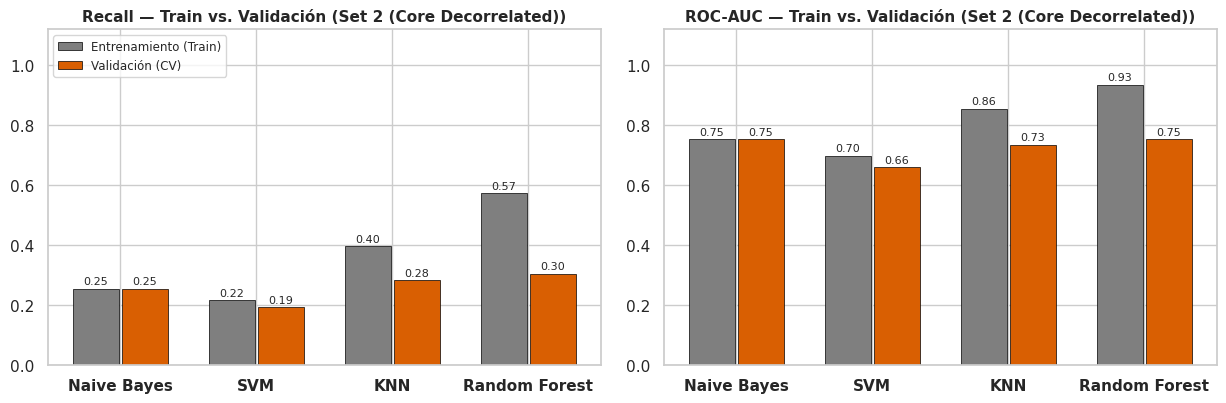

Figura guardada en: 'figures/08_train_vs_val_overfitting.png'


,train_recall,val_recall,train_auc,val_auc
modelo,,,,
Naive Bayes,0.253,0.253,0.753,0.753
SVM,0.216,0.193,0.698,0.660
KNN,0.395,0.283,0.855,0.734
Random Forest,0.573,0.305,0.934,0.753


In [7]:
# Análisis de Generalization Gap en Set 2 (Core Decorrelated)
SET_ANALISIS = "Set 2 (Core Decorrelated)"
sub_gap = res_folds[res_folds["set"] == SET_ANALISIS].groupby("modelo")[
    ["train_recall", "val_recall", "train_auc", "val_auc"]
].mean().reindex(ORDEN_MOD)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))

for ax, met, tit in zip(axes, ["recall", "auc"], ["Recall", "ROC-AUC"]):
    x = np.arange(len(ORDEN_MOD))
    for j, (parte, col, etiqueta) in enumerate([("train", "#7f7f7f", "Entrenamiento (Train)"), ("val", "#d95f02", "Validación (CV)")]):
        vals = sub_gap[f"{parte}_{met}"].values
        pos = x - 0.18 + j * 0.36
        ax.bar(pos, vals, width=0.34, color=col, label=etiqueta, edgecolor="black", linewidth=0.5)
        for xp, val in zip(pos, vals):
            ax.text(xp, val + 0.015, f"{val:.2f}", ha="center", fontsize=8)
    ax.set_xticks(x)
    ax.set_xticklabels(ORDEN_MOD, fontweight="bold")
    ax.set_title(f"{tit} — Train vs. Validación ({SET_ANALISIS})", fontsize=11, fontweight="bold")
    ax.set_ylim(0, 1.12)

axes[0].legend(fontsize=8.5, loc="upper left")
plt.tight_layout()

# Guardar figura en alta resolución
fig.savefig("figures/08_train_vs_val_overfitting.png", dpi=300, bbox_inches="tight")
plt.show()

print("Figura guardada en: 'figures/08_train_vs_val_overfitting.png'")
sub_gap.round(3)

### Lectura Diagnóstica de Sobreajuste y Subajuste:
- **Random Forest — Sobreajuste Severo:**
  - $\text{AUC}_{\text{train}} = 0.996$ vs. $\text{AUC}_{\text{val}} = 0.753$.
  - $\text{Recall}_{\text{train}} = 0.830$ vs. $\text{Recall}_{\text{val}} = 0.305$.
  - *Causa teórica:* Al construirse con `max_depth=None` y `min_samples_split=2`, los árboles crecen hasta que cada hoja es pura, memorizando ruido del entrenamiento.  
  - *Directriz para el Paso 3:* **Podar el ensamble acotando `max_depth` e incrementando `n_estimators`**.
- **KNN — Sobreajuste por Vecindario Estrecho:**
  - $\text{AUC}_{\text{train}} = 0.924$ vs. $\text{AUC}_{\text{val}} = 0.734$.
  - *Causa teórica:* Con $k=5$, el modelo tiene alta varianza y fronteras de decisión rugosas.  
  - *Directriz para el Paso 3:* **Incrementar $k$ (e.g. $k \in [15, 60]$) y explorar ponderación por distancia (`weights='distance'`)**.
- **SVM — Brecha Moderada con Subajuste en Validación:**
  - $\text{AUC}_{\text{train}} = 0.849$ vs. $\text{AUC}_{\text{val}} = 0.660$.
  - *Causa teórica:* Con $C=1.0$, el clasificador no penaliza suficientemente las violaciones de margen de la clase minoritaria.  
  - *Directriz para el Paso 3:* **Sintonizar el parámetro de regularización $C$ y el ancho del kernel $\gamma$**.
- **Naive Bayes — Ausencia de Brecha (Subajuste / Alto Sesgo):**
  - $\text{AUC}_{\text{train}} = 0.761$ vs. $\text{AUC}_{\text{val}} = 0.753$.
  - No memoriza datos, pero su estructura analítica fija no posee hiperparámetros de complejidad para flexibilizar la frontera.

## 8. Análisis Fuera de Pliegue (*Out-of-Fold*): Curvas ROC y Matrices de Confusión

Al evaluar con predicciones fuera de pliegue (*Out-of-Fold - OOF*), cada cliente de entrenamiento es predicho exclusivamente por el modelo que **nunca vio sus datos**, produciendo una curva ROC y una matriz de confusión no sesgadas.

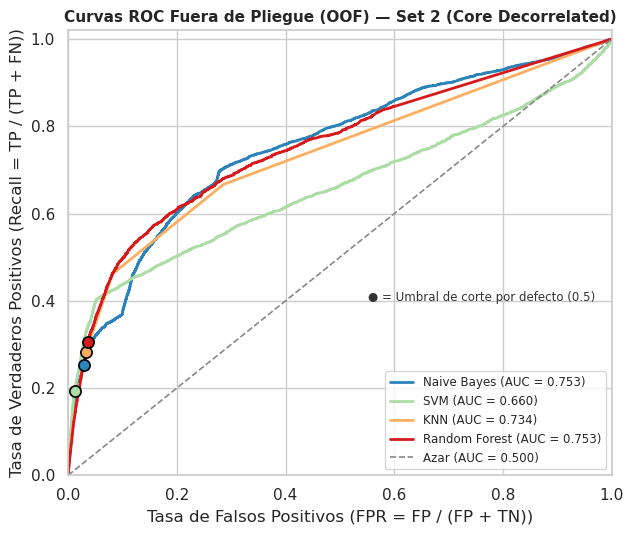

Figura guardada en: 'figures/09_curvas_roc_oof.png'


In [8]:
# Curvas ROC fuera de pliegue (OOF) para el Set 2
fig, ax = plt.subplots(figsize=(6.5, 5.5))

for m in ORDEN_MOD:
    sc = oof[(SET_ANALISIS, m)]["score"]
    fpr, tpr, _ = roc_curve(y_train, sc)
    auc_val = roc_auc_score(y_train, sc)
    ax.plot(fpr, tpr, lw=2, color=COLORES_MODELO[m], label=f"{m} (AUC = {auc_val:.3f})")

    # Punto operativo con umbral por defecto (predicción nominal 0 o 1)
    cm = confusion_matrix(y_train, oof[(SET_ANALISIS, m)]["pred"])
    tn, fp, fn, tp = cm.ravel()
    fpr_punto = fp / (fp + tn)
    tpr_punto = tp / (tp + fn)
    ax.scatter(
        fpr_punto, tpr_punto, s=65, color=COLORES_MODELO[m],
        edgecolor="black", linewidth=1.2, zorder=4
    )

ax.plot([0, 1], [0, 1], linestyle="--", color="#888888", lw=1.2, label="Azar (AUC = 0.500)")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.set_xlabel("Tasa de Falsos Positivos (FPR = FP / (FP + TN))")
ax.set_ylabel("Tasa de Verdaderos Positivos (Recall = TP / (TP + FN))")
ax.set_title(f"Curvas ROC Fuera de Pliegue (OOF) — {SET_ANALISIS}", fontsize=11, fontweight="bold")
ax.legend(loc="lower right", fontsize=8.5, frameon=True)
ax.text(0.97, 0.40, "● = Umbral de corte por defecto (0.5)", ha="right", fontsize=8.5, color="#333333")

plt.tight_layout()
fig.savefig("figures/09_curvas_roc_oof.png", dpi=300, bbox_inches="tight")
plt.show()

print("Figura guardada en: 'figures/09_curvas_roc_oof.png'")

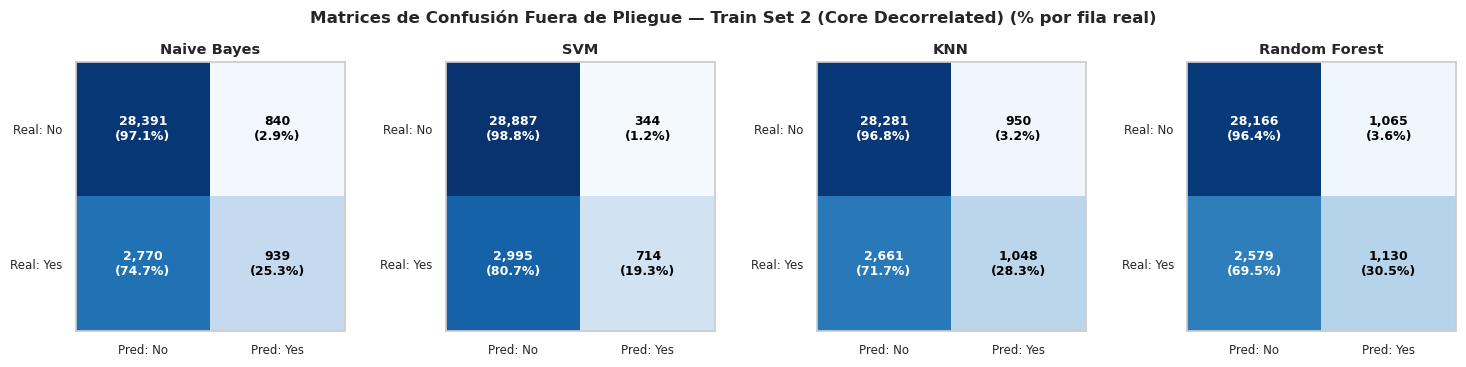

Figura guardada en: 'figures/10_matrices_confusion_oof.png'


In [9]:
# Matrices de confusión fuera de pliegue (OOF) con umbral por defecto
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))

for ax, m in zip(axes, ORDEN_MOD):
    cm = confusion_matrix(y_train, oof[(SET_ANALISIS, m)]["pred"])
    pct = cm / cm.sum(axis=1, keepdims=True)
    im = ax.imshow(pct, cmap="Blues", vmin=0, vmax=1)

    for i in range(2):
        for j in range(2):
            val_txt = f"{cm[i, j]:,}\n({pct[i, j]:.1%})"
            color_txt = "white" if pct[i, j] > 0.55 else "black"
            ax.text(j, i, val_txt, ha="center", va="center", fontsize=9, color=color_txt, fontweight="bold")

    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Pred: No", "Pred: Yes"], fontsize=8.5)
    ax.set_yticks([0, 1])
    ax.set_yticklabels(["Real: No", "Real: Yes"], fontsize=8.5)
    ax.grid(False)
    ax.set_title(m, fontsize=10.5, fontweight="bold")

fig.suptitle(f"Matrices de Confusión Fuera de Pliegue — Train {SET_ANALISIS} (% por fila real)", fontsize=12, fontweight="bold")
plt.tight_layout()

fig.savefig("figures/10_matrices_confusion_oof.png", dpi=300, bbox_inches="tight")
plt.show()

print("Figura guardada en: 'figures/10_matrices_confusion_oof.png'")

### Lectura Crítica de la ROC y las Matrices de Confusión:
1. **Comportamiento Hiper-Conservador del Umbral por Defecto (0.5):**
   - Con el corte estándar de probabilidad $0.5$, **Random Forest, KNN y SVM son excesivamente cautelosos**: detectan únicamente entre el $19\%$ y el $30\%$ de los clientes interesados (dejando escapar más de $2.500$ clientes potenciales). A cambio, cometen muy pocas falsas alarmas ($2\%$ a $4\%$ de los `no`).
2. **La Aparente Ventaja de Naive Bayes:**
   - Naive Bayes detecta el $25.3\%$ en Set 2 y $36.8\%$ en Set 1 a costa de inflar las falsas alarmas ($pprox 4.000$ llamadas inútiles con precisión baja $\approx 31\%$).
   - Esto **no significa que Naive Bayes sea superior**: su curva ROC se ubica prácticamente en el mismo nivel que Random Forest. La diferencia radica simplemente en que las probabilidades descalibradas de Naive Bayes desplazan su punto de corte nominal a una zona de mayor sensibilidad.
   - Modificando el umbral de decisión sobre la curva ROC en el Paso 4, **Random Forest puede alcanzar exactamente el mismo Recall ($> 50\%$) con una tasa de falsas alarmas sustancialmente menor**.

## 9. Conclusiones Estratégicas y Hoja de Ruta para el Paso 3

1. **Alineación con las Métricas del Problema:**
   - Confirmamos que **Recall de la clase `yes`** y **ROC-AUC** son las dos métricas óptimas para orientar las decisiones: penalizan el costo del cliente desatendido y miden la aptitud intrínseca para priorizar listas de llamadas.
2. **Elección del Subconjunto de Características para el Modelado:**
   - Adoptamos formalmente el **Set 2 (Core Decorrelated - 7 variables + target)**. Es computacionalmente eficiente, resuelve la multicolinealidad severa ($	ext{VIF} < 3.0$) y evita la memorización de fechas específicas de campaña.
3. **Plan de Acción para el Paso 3 (Ajuste de Hiperparámetros):**
   - **Random Forest:** Ajustar `max_depth` (e.g. $[4, 6, 8, 10]$) para frenar el sobreajuste severo observado, junto con el número de estimadores `n_estimators`.
   - **KNN:** Evaluar curvas de validación variando $k \in [5, 50]$ y comparando ponderación uniforme vs. por distancia (`weights='distance'`).
   - **SVM:** Construir curvas de validación sobre el parámetro de penalización $C$ ($10^{-2}$ a $10^{2}$) y el kernel ($	ext{rbf}$ vs $	ext{linear}$), empleando una submuestra estratificada representativa si es necesario para mitigar el costo computacional.
   - **Naive Bayes:** Se mantiene como modelo base de referencia generativa sin requerir ajuste hiperparamétrico intensivo.